# 🛠 Kestirimci Bakım: Makine Arızası Tahmini (ML + DL)
**Makine ve Derin Öğrenme Uygulamaları — Proje**
Hazırlayan: **Fatih Okur** · Software Persona Yapay Zeka Mesleki Gelişim Programı · 2026

[![Colab'da Aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FatihOkur/Software-Persona-Projects/blob/main/04-Makine-ve-Derin-Ogrenme/kestirimci_bakim.ipynb)

**Veri seti:** AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository (CC BY 4.0)
https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

**Karşılaştırılan modeller:** Lojistik Regresyon (temel model) · Random Forest · PyTorch çok katmanlı yapay sinir ağı (MLP)

## 1. Problem Tanımı
Üretim hatlarında (ve havacılık bakımında) plansız makine arızaları; üretim kaybına, yüksek onarım maliyetine
ve güvenlik riskine yol açar. Bu projede bir freze tezgâhının **sensör ölçümlerinden** (hava ve işlem sıcaklığı,
dönüş hızı, tork, takım aşınması ve ürün kalitesi tipi) makinenin **arızalanıp arızalanmayacağını** tahmin eden
bir sınıflandırma modeli geliştirilir. Girdi: 6 sensör/ürün özelliği. Çıktı: `Machine failure` (1 = arıza, 0 = normal).
Gerçek dünya ihtiyacı: arızayı önceden yakalayarak bakımı **planlı** hâle getirmek. Bu yüzden arızaları kaçırmamak
(**recall**) en kritik metriktir.

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   # paralel işçilerdeki uyarıları da bastır
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
os.makedirs("grafikler", exist_ok=True)
SEED = 42
np.random.seed(SEED)

VERI_URL = ("https://raw.githubusercontent.com/FatihOkur/Software-Persona-Projects/"
            "main/04-Makine-ve-Derin-Ogrenme/veri/ai4i2020.csv")
kaynak = "veri/ai4i2020.csv" if os.path.exists("veri/ai4i2020.csv") else VERI_URL
df = pd.read_csv(kaynak)
print("Boyut:", df.shape)
df.head()

Boyut: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Veri Setinin Tanıtılması

In [2]:
df.info()
print("\nEksik değer toplamı:", int(df.isnull().sum().sum()))
print("Tekrar eden satır:", int(df.duplicated().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [3]:
print("Hedef dağılımı (Machine failure):")
print(df["Machine failure"].value_counts())
print(f"Arıza oranı: %{df['Machine failure'].mean()*100:.2f}  → ciddi sınıf dengesizliği")
print("\nArıza modları (TWF, HDF, PWF, OSF, RNF):")
print(df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())

Hedef dağılımı (Machine failure):
Machine failure
0    9661
1     339
Name: count, dtype: int64
Arıza oranı: %3.39  → ciddi sınıf dengesizliği

Arıza modları (TWF, HDF, PWF, OSF, RNF):
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


| Değişken | Tip | Açıklama |
|---|---|---|
| Type | kategorik (L/M/H) | Ürün kalite varyantı (düşük %50, orta %30, yüksek %20) |
| Air temperature [K] | sayısal | Ortam sıcaklığı |
| Process temperature [K] | sayısal | İşlem sıcaklığı |
| Rotational speed [rpm] | sayısal | Mil dönüş hızı |
| Torque [Nm] | sayısal | Tork |
| Tool wear [min] | sayısal | Takım aşınma süresi |
| **Machine failure** | hedef (0/1) | Makine arızası |
| TWF, HDF, PWF, OSF, RNF | 0/1 | Arıza **modları** (takım aşınması, ısı dağılımı, güç, aşırı zorlanma, rastgele) |

⚠️ **Veri sızıntısı uyarısı:** Arıza modu sütunları hedefin *nedenini* doğrudan söyler; tahmin anında bilinemezler.
Bu yüzden modele **girdi olarak verilmez**, yalnızca **hata analizinde** kullanılır. `UDI` ve `Product ID` kimlik sütunlarıdır, çıkarılır.

## 3. Veri Keşfi (EDA)

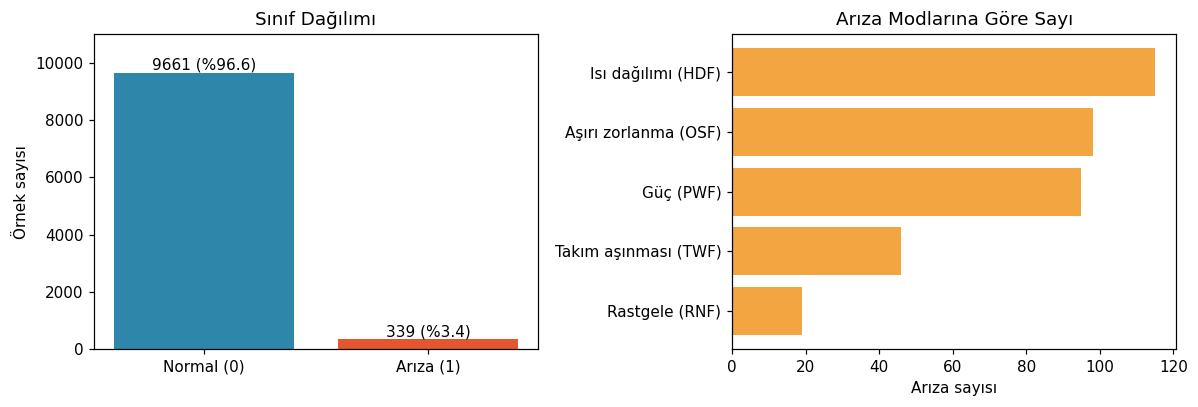

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
vc = df["Machine failure"].value_counts()
ax[0].bar(["Normal (0)", "Arıza (1)"], vc.values, color=["#2E86AB", "#E4572E"])
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 120, f"{v} (%{v/len(df)*100:.1f})", ha="center")
ax[0].set_title("Sınıf Dağılımı"); ax[0].set_ylabel("Örnek sayısı"); ax[0].set_ylim(0, 11000)

modlar = df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum().sort_values()
etiket = {"TWF": "Takım aşınması (TWF)", "HDF": "Isı dağılımı (HDF)", "PWF": "Güç (PWF)",
          "OSF": "Aşırı zorlanma (OSF)", "RNF": "Rastgele (RNF)"}
ax[1].barh([etiket[m] for m in modlar.index], modlar.values, color="#F2A541")
ax[1].set_title("Arıza Modlarına Göre Sayı"); ax[1].set_xlabel("Arıza sayısı")
plt.tight_layout(); plt.savefig("grafikler/1_sinif_dagilimi.png", dpi=150); plt.show()

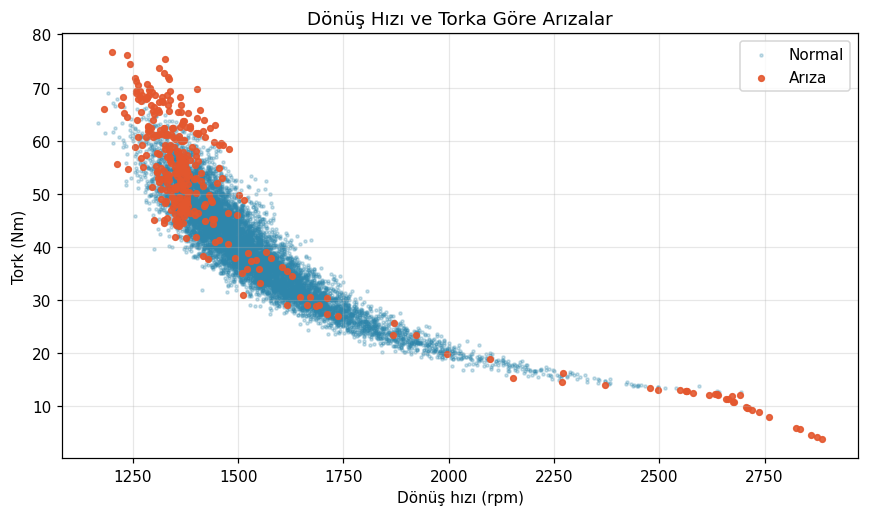

In [5]:
# Tork ve dönüş hızı: arızalar nerede yoğunlaşıyor?
plt.figure(figsize=(8, 4.8))
n = df[df["Machine failure"] == 0]; a = df[df["Machine failure"] == 1]
plt.scatter(n["Rotational speed [rpm]"], n["Torque [Nm]"], s=4, alpha=0.25, c="#2E86AB", label="Normal")
plt.scatter(a["Rotational speed [rpm]"], a["Torque [Nm]"], s=14, alpha=0.9, c="#E4572E", label="Arıza")
plt.title("Dönüş Hızı ve Torka Göre Arızalar")
plt.xlabel("Dönüş hızı (rpm)"); plt.ylabel("Tork (Nm)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("grafikler/2_tork_hiz.png", dpi=150); plt.show()

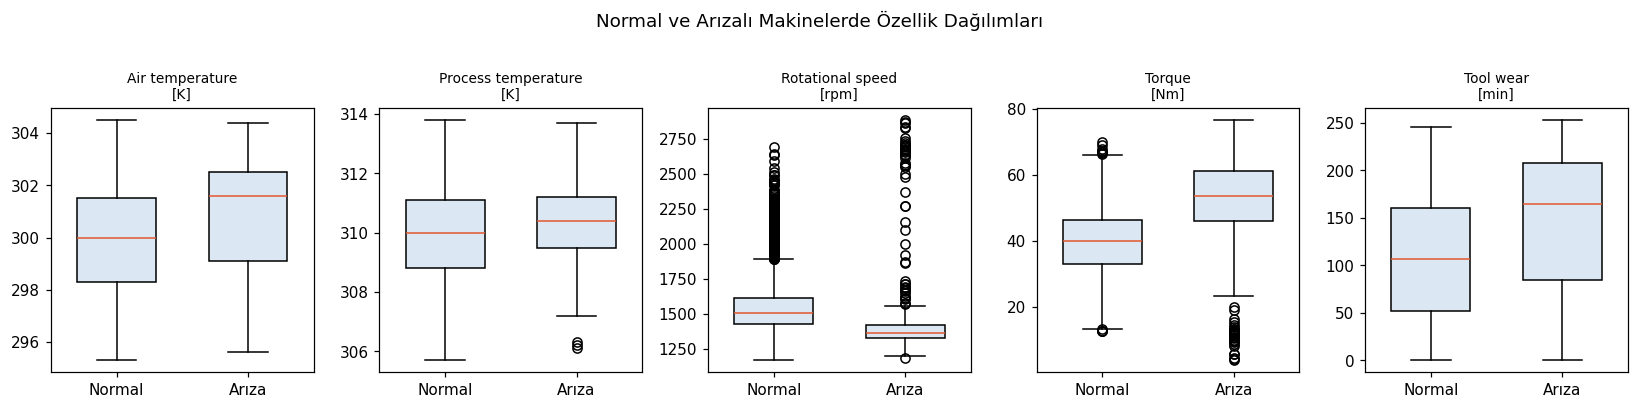

Ürün tipine göre arıza oranı (%):
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


In [6]:
# Özellik dağılımları: normal ve arızalı örneklerde kutu grafikleri
ozellikler = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for ax_, col in zip(axes, ozellikler):
    ax_.boxplot([n[col], a[col]], tick_labels=["Normal", "Arıza"], widths=0.6,
                patch_artist=True, boxprops=dict(facecolor="#dbe8f3"), medianprops=dict(color="#E4572E"))
    ax_.set_title(col.replace(" [", "\n["), fontsize=9)
plt.suptitle("Normal ve Arızalı Makinelerde Özellik Dağılımları", y=1.02)
plt.tight_layout(); plt.savefig("grafikler/3_kutu_grafikleri.png", dpi=150, bbox_inches="tight"); plt.show()

print("Ürün tipine göre arıza oranı (%):")
print((df.groupby("Type")["Machine failure"].mean() * 100).round(2))

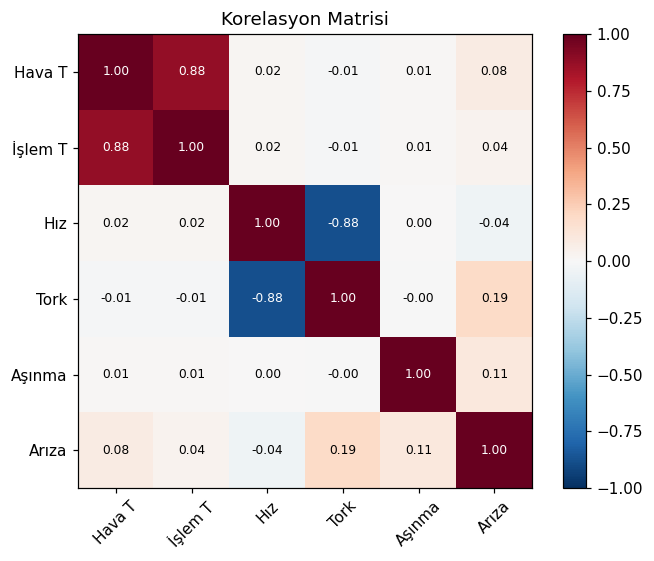

In [7]:
# Korelasyon matrisi
sayisal = df[ozellikler + ["Machine failure"]]
kor = sayisal.corr()
plt.figure(figsize=(6.5, 5.2))
plt.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
kisa = ["Hava T", "İşlem T", "Hız", "Tork", "Aşınma", "Arıza"]
plt.xticks(range(6), kisa, rotation=45); plt.yticks(range(6), kisa)
for i in range(6):
    for j in range(6):
        plt.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if abs(kor.iloc[i, j]) > 0.5 else "black")
plt.colorbar(fraction=0.046); plt.title("Korelasyon Matrisi")
plt.tight_layout(); plt.savefig("grafikler/4_korelasyon.png", dpi=150); plt.show()

## 4. Veri Ön İşleme ve Özellik Mühendisliği

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

veri = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]).copy()

# Alan bilgisine dayalı yeni özellikler (fiziksel anlamı olan)
veri["Sicaklik farki [K]"] = veri["Process temperature [K]"] - veri["Air temperature [K]"]          # ısı dağılımı
veri["Guc [W]"] = veri["Torque [Nm]"] * veri["Rotational speed [rpm]"] * 2 * np.pi / 60             # mekanik güç
veri["Zorlanma [min*Nm]"] = veri["Tool wear [min]"] * veri["Torque [Nm]"]                          # aşınma × tork

# Encoding: ürün tipi (L/M/H) one-hot kodlanır
veri = pd.get_dummies(veri, columns=["Type"], prefix="Tip", dtype=int)

y = veri.pop("Machine failure").values
X = veri
OZ = list(X.columns)
print("Özellikler:", OZ)

# Bölme: %70 eğitim, %15 doğrulama, %15 test — stratify ile arıza oranı korunur
X_tmp, X_test, y_tmp, y_test, idx_tmp, idx_test = train_test_split(
    X, y, X.index, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)

# Ölçekleme: yalnızca eğitim verisine fit edilir (sızıntıyı önlemek için)
scaler = StandardScaler().fit(X_train)
Xtr_s, Xval_s, Xte_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

for ad, yy in [("Eğitim", y_train), ("Doğrulama", y_val), ("Test", y_test)]:
    print(f"{ad:10s}: {len(yy):5d} örnek, {yy.sum():3d} arıza (%{yy.mean()*100:.2f})")

Özellikler: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Sicaklik farki [K]', 'Guc [W]', 'Zorlanma [min*Nm]', 'Tip_H', 'Tip_L', 'Tip_M']
Eğitim    :  7000 örnek, 237 arıza (%3.39)
Doğrulama :  1500 örnek,  51 arıza (%3.40)
Test      :  1500 örnek,  51 arıza (%3.40)


## 5. Model Seçimi ve 6. Model Eğitimi

### 5.1 Temel model — Lojistik Regresyon

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve)

def olc(ad, y_true, olasilik, esik=0.5):
    tahmin = (olasilik >= esik).astype(int)
    return {"Model": ad, "Accuracy": accuracy_score(y_true, tahmin),
            "Precision": precision_score(y_true, tahmin, zero_division=0),
            "Recall": recall_score(y_true, tahmin), "F1": f1_score(y_true, tahmin),
            "ROC-AUC": roc_auc_score(y_true, olasilik), "PR-AUC": average_precision_score(y_true, olasilik)}

lr = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
lr.fit(Xtr_s, y_train)
print("Doğrulama:", {k: round(v, 3) for k, v in olc("LR", y_val, lr.predict_proba(Xval_s)[:, 1]).items() if k != "Model"})

Doğrulama: {'Accuracy': 0.835, 'Precision': 0.139, 'Recall': 0.745, 'F1': 0.235, 'ROC-AUC': 0.885, 'PR-AUC': 0.353}


### 5.2 Random Forest — çapraz doğrulamalı hiperparametre ayarı

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    param_grid={"max_depth": [8, 12, None], "min_samples_leaf": [1, 3, 5]},
    scoring="f1", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
t0 = time.time(); grid.fit(X_train, y_train)
rf = grid.best_estimator_
print("En iyi parametreler:", grid.best_params_, f"| CV F1: {grid.best_score_:.3f} | süre: {time.time()-t0:.0f} sn")
print("Doğrulama:", {k: round(v, 3) for k, v in olc("RF", y_val, rf.predict_proba(X_val)[:, 1]).items() if k != "Model"})

En iyi parametreler: {'max_depth': 12, 'min_samples_leaf': 3} | CV F1: 0.860 | süre: 85 sn


Doğrulama: {'Accuracy': 0.989, 'Precision': 0.886, 'Recall': 0.765, 'F1': 0.821, 'ROC-AUC': 0.955, 'PR-AUC': 0.84}


### 5.3 Derin öğrenme — PyTorch MLP
**Mimari:** Girdi (11) → Dense 64 + ReLU + Dropout 0.2 → Dense 32 + ReLU + Dropout 0.2 → Dense 1 (logit)
**Loss:** `BCEWithLogitsLoss(pos_weight = normal/arıza oranı)` — azınlık sınıfa daha fazla ağırlık verir
**Optimizer:** Adam (lr = 0.001, weight_decay = 1e-4) · **Batch size:** 128 · **Epoch:** en fazla 150, doğrulama
PR-AUC'si 20 epoch iyileşmezse **erken durdurma** (en iyi ağırlıklar geri yüklenir).

In [11]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(SEED)

class MLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.ag = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(0.2),
                                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
                                nn.Linear(32, 1))
    def forward(self, x):
        return self.ag(x).squeeze(1)

T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
yukleyici = DataLoader(TensorDataset(T(Xtr_s), T(y_train)), batch_size=128, shuffle=True,
                       generator=torch.Generator().manual_seed(SEED))
mlp = MLP(Xtr_s.shape[1])
pos_weight = torch.tensor((y_train == 0).sum() / (y_train == 1).sum(), dtype=torch.float32)
kayip_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)

gecmis = {"egitim_kayip": [], "dogr_kayip": [], "dogr_prauc": [], "dogr_f1": []}
en_iyi, en_iyi_durum, sabir = -1, None, 0
for epoch in range(1, 151):
    mlp.train(); toplam = 0
    for xb, yb in yukleyici:
        opt.zero_grad(); kayip = kayip_fn(mlp(xb), yb); kayip.backward(); opt.step()
        toplam += kayip.item() * len(xb)
    mlp.eval()
    with torch.no_grad():
        logit = mlp(T(Xval_s)); p_val = torch.sigmoid(logit).numpy()
        gecmis["dogr_kayip"].append(kayip_fn(logit, T(y_val)).item())
    gecmis["egitim_kayip"].append(toplam / len(y_train))
    prauc = average_precision_score(y_val, p_val)
    gecmis["dogr_prauc"].append(prauc); gecmis["dogr_f1"].append(f1_score(y_val, p_val >= 0.5))
    if prauc > en_iyi:
        en_iyi, en_iyi_epoch, sabir = prauc, epoch, 0
        en_iyi_durum = {k: v.clone() for k, v in mlp.state_dict().items()}
    else:
        sabir += 1
        if sabir >= 20:
            break
mlp.load_state_dict(en_iyi_durum); mlp.eval()
print(f"Eğitim {epoch}. epoch'ta durdu | en iyi epoch: {en_iyi_epoch} | doğrulama PR-AUC: {en_iyi:.3f}")

def mlp_olasilik(Xs):
    with torch.no_grad():
        return torch.sigmoid(mlp(T(Xs))).numpy()

Eğitim 116. epoch'ta durdu | en iyi epoch: 96 | doğrulama PR-AUC: 0.707


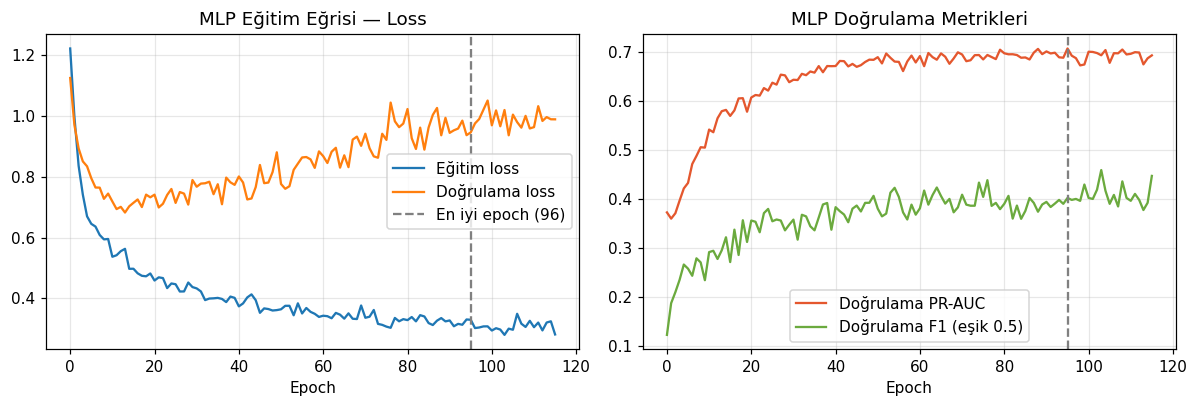

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(gecmis["egitim_kayip"], label="Eğitim loss"); ax[0].plot(gecmis["dogr_kayip"], label="Doğrulama loss")
ax[0].axvline(en_iyi_epoch - 1, ls="--", c="gray", label=f"En iyi epoch ({en_iyi_epoch})")
ax[0].set_title("MLP Eğitim Eğrisi — Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(gecmis["dogr_prauc"], label="Doğrulama PR-AUC", c="#E4572E")
ax[1].plot(gecmis["dogr_f1"], label="Doğrulama F1 (eşik 0.5)", c="#6BAA3E")
ax[1].axvline(en_iyi_epoch - 1, ls="--", c="gray")
ax[1].set_title("MLP Doğrulama Metrikleri"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("grafikler/5_mlp_egitim.png", dpi=150); plt.show()

### 5.4 Karar eşiğinin ayarlanması
Varsayılan 0,5 eşiği dengesiz veride en iyi seçim olmayabilir. Her model için eşik, **doğrulama kümesinde F1'i
en yüksek yapan** değere ayarlanır; test kümesine yalnızca en sonda bakılır.

In [13]:
def en_iyi_esik(y_true, olasilik):
    p, r, t = precision_recall_curve(y_true, olasilik)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

olasiliklar_val = {"Lojistik Regresyon": lr.predict_proba(Xval_s)[:, 1],
                   "Random Forest": rf.predict_proba(X_val)[:, 1],
                   "MLP (PyTorch)": mlp_olasilik(Xval_s)}
esikler = {ad: en_iyi_esik(y_val, p) for ad, p in olasiliklar_val.items()}
print({k: round(v, 3) for k, v in esikler.items()})

{'Lojistik Regresyon': 0.857, 'Random Forest': 0.639, 'MLP (PyTorch)': 0.957}


## 7. Model Değerlendirme (test kümesi)

In [14]:
olasiliklar_test = {"Lojistik Regresyon": lr.predict_proba(Xte_s)[:, 1],
                    "Random Forest": rf.predict_proba(X_test)[:, 1],
                    "MLP (PyTorch)": mlp_olasilik(Xte_s)}
sonuc = pd.DataFrame([olc(ad, y_test, p, esikler[ad]) for ad, p in olasiliklar_test.items()]).set_index("Model")
sonuc.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Lojistik Regresyon,0.954,0.382,0.569,0.457,0.948,0.461
Random Forest,0.995,0.978,0.863,0.917,0.989,0.939
MLP (PyTorch),0.980,0.744,0.627,0.681,0.978,0.779


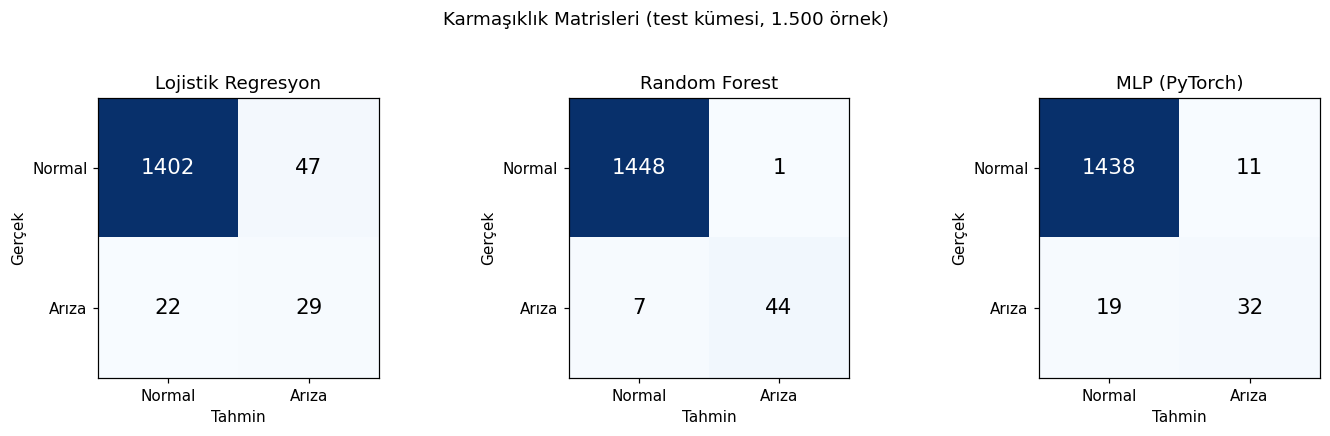

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax_, (ad, p) in zip(axes, olasiliklar_test.items()):
    cm = confusion_matrix(y_test, (p >= esikler[ad]).astype(int))
    ax_.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax_.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax_.set_xticks([0, 1], ["Normal", "Arıza"]); ax_.set_yticks([0, 1], ["Normal", "Arıza"])
    ax_.set_xlabel("Tahmin"); ax_.set_ylabel("Gerçek"); ax_.set_title(ad)
plt.suptitle("Karmaşıklık Matrisleri (test kümesi, 1.500 örnek)", y=1.03)
plt.tight_layout(); plt.savefig("grafikler/6_karmasiklik.png", dpi=150, bbox_inches="tight"); plt.show()

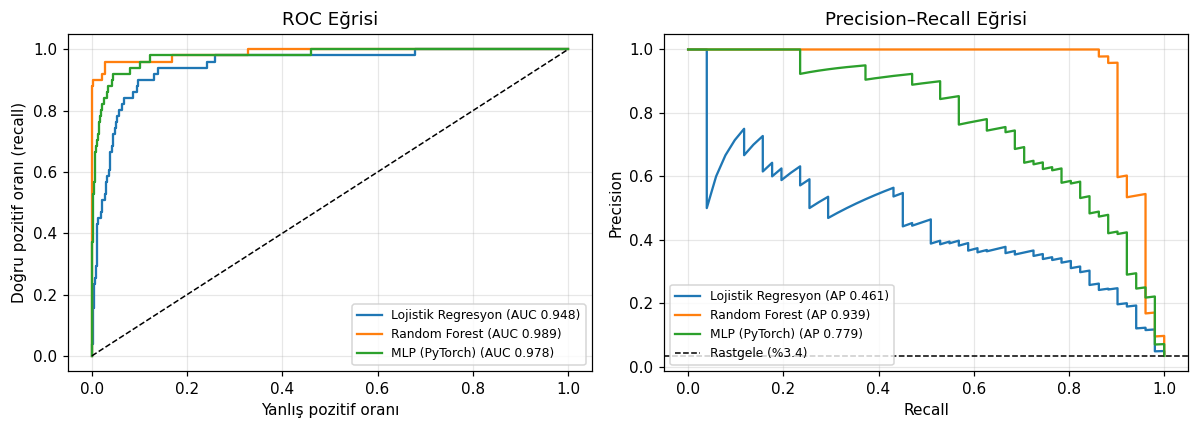

In [16]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for ad, p in olasiliklar_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{ad} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{ad} (AP {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC Eğrisi"); ax[0].set_xlabel("Yanlış pozitif oranı"); ax[0].set_ylabel("Doğru pozitif oranı (recall)")
ax[1].axhline(y_test.mean(), c="k", ls="--", lw=1, label=f"Rastgele (%{y_test.mean()*100:.1f})")
ax[1].set_title("Precision–Recall Eğrisi"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
for a_ in ax: a_.legend(fontsize=8); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig("grafikler/7_roc_pr.png", dpi=150); plt.show()

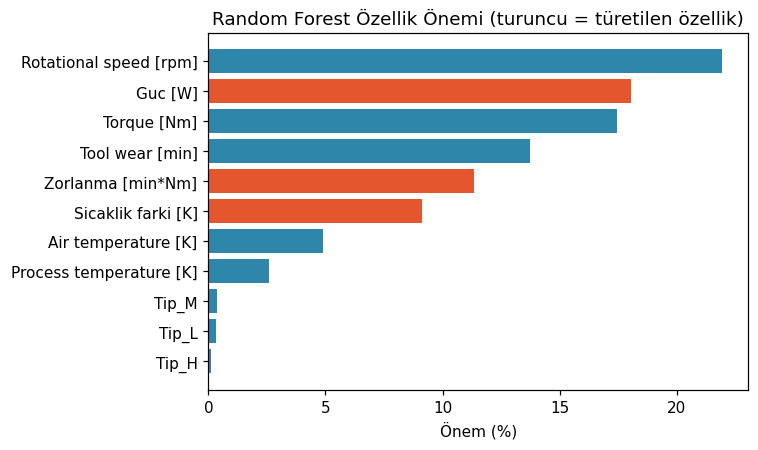

Rotational speed [rpm]     21.9
Guc [W]                    18.1
Torque [Nm]                17.5
Tool wear [min]            13.7
Zorlanma [min*Nm]          11.3
Sicaklik farki [K]          9.1
Air temperature [K]         4.9
Process temperature [K]     2.6
Tip_M                       0.4
Tip_L                       0.3
Tip_H                       0.1
dtype: float64

In [17]:
onem = pd.Series(rf.feature_importances_, index=OZ).sort_values()
plt.figure(figsize=(7, 4.2))
plt.barh(onem.index, onem.values * 100, color=["#E4572E" if i in ["Guc [W]", "Zorlanma [min*Nm]", "Sicaklik farki [K]"] else "#2E86AB" for i in onem.index])
plt.title("Random Forest Özellik Önemi (turuncu = türetilen özellik)"); plt.xlabel("Önem (%)")
plt.tight_layout(); plt.savefig("grafikler/8_ozellik_onemi.png", dpi=150); plt.show()
(onem.sort_values(ascending=False) * 100).round(1)

In [18]:
# Ablasyon: türetilen özellikler olmadan Random Forest ne kadar başarılı?
ham = [c for c in OZ if c not in ["Sicaklik farki [K]", "Guc [W]", "Zorlanma [min*Nm]"]]
rf_ham = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1,
                                random_state=SEED, **grid.best_params_).fit(X_train[ham], y_train)
esik_ham = en_iyi_esik(y_val, rf_ham.predict_proba(X_val[ham])[:, 1])
pd.DataFrame([olc("RF — yalnızca ham özellikler", y_test, rf_ham.predict_proba(X_test[ham])[:, 1], esik_ham),
              olc("RF — ham + türetilen özellikler", y_test, olasiliklar_test["Random Forest"], esikler["Random Forest"])]
            ).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
RF — yalnızca ham özellikler,0.981,0.712,0.725,0.718,0.968,0.760
RF — ham + türetilen özellikler,0.995,0.978,0.863,0.917,0.989,0.939


## 8. Hata Analizi — model hangi arızaları kaçırıyor?

In [19]:
en_iyi_model = sonuc["F1"].idxmax()
p = olasiliklar_test[en_iyi_model]; tahmin = (p >= esikler[en_iyi_model]).astype(int)
test_df = df.loc[idx_test].copy(); test_df["tahmin"] = tahmin; test_df["olasilik"] = p

satirlar = []
for mod in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    alt = test_df[(test_df[mod] == 1) & (test_df["Machine failure"] == 1)]
    if len(alt):
        satirlar.append({"Arıza modu": mod, "Test'teki arıza": len(alt), "Yakalanan": int(alt["tahmin"].sum()),
                         "Yakalama oranı %": round(alt["tahmin"].mean() * 100, 1)})
print("En iyi model (F1):", en_iyi_model)
hata_mod = pd.DataFrame(satirlar).set_index("Arıza modu"); hata_mod

En iyi model (F1): Random Forest


,Test'teki arıza,Yakalanan,Yakalama oranı %
Arıza modu,,,
TWF,5,1,20.0
HDF,21,19,90.5
PWF,11,11,100.0
OSF,15,15,100.0


In [20]:
yp = test_df[(test_df["Machine failure"] == 0) & (test_df["tahmin"] == 1)]
yn = test_df[(test_df["Machine failure"] == 1) & (test_df["tahmin"] == 0)]
print(f"Yanlış alarm (FP): {len(yp)} | Kaçırılan arıza (FN): {len(yn)}")
print("\nKaçırılan arızaların özellikleri:")
yn[["Type", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", "TWF", "HDF", "PWF", "OSF", "RNF", "olasilik"]].round(3)

Yanlış alarm (FP): 1 | Kaçırılan arıza (FN): 7

Kaçırılan arızaların özellikleri:


,Type,Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,olasilik
4078,H,1294,62.4,101,0,1,0,0,0,0.568
1996,M,1416,38.2,198,1,0,0,0,0,0.018
4034,L,1615,29.0,235,1,0,0,0,0,0.235
3695,L,1530,37.3,207,1,0,0,0,0,0.231
7087,L,1648,30.5,217,1,0,0,0,0,0.273
4307,L,1259,63.9,20,0,1,0,0,0,0.613
8506,L,1710,27.3,163,0,0,0,0,0,0.003


In [21]:
print("Yanlış alarmların ortalama değerleri ve tüm normal örneklerle karşılaştırma:")
pd.DataFrame({"Yanlış alarmlar": yp[ozellikler].mean(),
              "Tüm normal örnekler": df[df["Machine failure"] == 0][ozellikler].mean()}).round(1)

Yanlış alarmların ortalama değerleri ve tüm normal örneklerle karşılaştırma:


,Yanlış alarmlar,Tüm normal örnekler
Air temperature [K],300.7,300.0
Process temperature [K],310.8,310.0
Rotational speed [rpm],1296.0,1540.3
Torque [Nm],58.2,39.6
Tool wear [min],204.0,106.7


## 9. Sonuç
Sonuçların yorumu, güçlü ve zayıf yönler ile geliştirme önerileri proje raporunda ayrıntılı olarak tartışılmıştır.